# YOLO11n — 대용량 학습



## 1. Google Drive 마운트 및 Ultralytics 설치

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!pip -q install -U ultralytics pyyaml pandas matplotlib

from ultralytics import YOLO
from google.colab import files
from pathlib import Path
from datetime import datetime
import json, shutil, zipfile, yaml, torch
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')

Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.6/46.6 kB 3.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 5.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 8.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 39.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 118.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 111.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.4/77.4 kB 7.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.5 which is incompatible.
cudf-cu12 26.2.1 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.5 which is incompatible.
dask-cudf-cu12 26.2.1 requires pandas<2.4.0,>=2.0, but you 

## 2. 설정


In [ ]:
# ============================================================
# 경로 및 학습 설정
# ============================================================
DRIVE_ROOT = Path('/content/drive/MyDrive/ai/final/model')
UPLOAD_ROOT = DRIVE_ROOT / 'data_upload'                  # chunk01.zip ~ chunk10.zip
VALIDATION_ZIP = DRIVE_ROOT / 'validation.zip'
VALIDATION_EXTRACT_DIR = DRIVE_ROOT / 'validation_extracted'
VALIDATION_SUBSET_ZIP = DRIVE_ROOT / 'validation_subset.zip'
VALIDATION_ROOT = Path('/content/validation_subset')       # 약 30GB: images/, labels/
TEST_ZIP = DRIVE_ROOT / 'test_subset.zip'                  # 약 60GB, 최종 평가 때만 압축 해제
RUNS_ROOT = DRIVE_ROOT / 'runs'
REPLAY_ROOT = DRIVE_ROOT / 'replay'
GLOBAL_BEST = DRIVE_ROOT / 'global_best.pt'
STATE_FILE = DRIVE_ROOT / 'training_state.json'
WORK_ROOT = DRIVE_ROOT / 'work'

CLASSES = ['PET', 'CAN', 'PAPER', 'VINYL']
BASE_MODEL = 'yolo11n.pt'                           # 기존과 동일
EPOCHS = 5
PATIENCE = 0                                      # 0이면 조기 종료 안 함
IMGSZ = 640
BATCH = 32                                         # GPU 메모리 부족 시 8/4
WORKERS = 2
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
REPLAY_IMAGES_PER_CHUNK = 300                       # 이전 청크 망각 완화
DELETE_EXTRACTED_CHUNK_AFTER_SUCCESS = True
DELETE_ZIP_FROM_DRIVE_AFTER_SUCCESS = False         # 확인 전 원본 ZIP 자동 삭제 금지

for p in [DRIVE_ROOT, UPLOAD_ROOT, RUNS_ROOT, REPLAY_ROOT/'images', REPLAY_ROOT/'labels', WORK_ROOT]:
    p.mkdir(parents=True, exist_ok=True)

print('YOLO 모델:', BASE_MODEL)
print('청크 ZIP 위치:', UPLOAD_ROOT)
print('고정 validation:', VALIDATION_ROOT)
print('최종 test ZIP:', TEST_ZIP)
print('전역 최고 모델:', GLOBAL_BEST)

# A100 런타임의 로컬 디스크는 시스템 파일 때문에 실제 여유 공간이 더 작습니다.
# 이 노트북의 대용량 압축 해제는 모두 Google Drive 작업 폴더를 사용합니다.
local_disk = shutil.disk_usage('/content')
print(f'Colab 로컬 디스크 여유: {local_disk.free / 1024**3:.1f} GB / 전체 {local_disk.total / 1024**3:.1f} GB')
print('대용량 작업 위치:', WORK_ROOT)


YOLO 모델: yolo11n.pt
청크 ZIP 위치: /content/drive/MyDrive/ai/final/model/data_upload
고정 validation: /content/validation_subset
최종 test ZIP: /content/drive/MyDrive/ai/final/model/test_subset.zip
전역 최고 모델: /content/drive/MyDrive/ai/final/model/global_best.pt
Colab 로컬 디스크 여유: 188.1 GB / 전체 235.7 GB
대용량 작업 위치: /content/drive/MyDrive/ai/final/model/work


## 3. 폴더 검사 및 상태 관리 함수


In [ ]:
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tif', '.tiff'}

def load_state():
    if STATE_FILE.exists():
        state = json.loads(STATE_FILE.read_text(encoding='utf-8'))
    else:
        state = {}
    state.setdefault('completed_chunks', [])
    state.setdefault('current_chunk', None)
    state.setdefault('global_best', str(GLOBAL_BEST) if GLOBAL_BEST.exists() else None)
    state.setdefault('global_best_map5095', -1.0)
    state.setdefault('history', [])
    return state

def save_state(state):
    state['updated_at'] = datetime.now().isoformat(timespec='seconds')
    tmp = STATE_FILE.with_suffix('.tmp')
    tmp.write_text(json.dumps(state, ensure_ascii=False, indent=2), encoding='utf-8')
    tmp.replace(STATE_FILE)

def locate_dataset_root(root):
    candidates = [root] + [p for p in root.rglob('*') if p.is_dir()]
    for p in candidates:
        if (p / 'images').is_dir() and (p / 'labels').is_dir():
            return p
    raise FileNotFoundError('ZIP 안에서 images/ 와 labels/ 폴더를 찾지 못했습니다.')

def validate_split(root, split_name, strict=True):
    images_dir, labels_dir = root / 'images', root / 'labels'
    if not images_dir.is_dir() or not labels_dir.is_dir():
        raise FileNotFoundError(f'{split_name}: images/ 또는 labels/ 폴더가 없습니다: {root}')
    images = [p for p in images_dir.rglob('*') if p.is_file() and p.suffix.lower() in IMAGE_EXTS]
    labels = [p for p in labels_dir.rglob('*.txt') if p.is_file()]
    if not images or not labels:
        raise ValueError(f'{split_name}: 이미지 또는 라벨이 비어 있습니다.')
    classes_file = root / 'classes.txt'
    if classes_file.exists():
        found = [x.strip() for x in classes_file.read_text(encoding='utf-8-sig').splitlines() if x.strip()]
        if found != CLASSES:
            raise ValueError(f'{split_name}: classes.txt 순서 오류. 필요={CLASSES}, 실제={found}')
        print(f'{split_name}: classes.txt 확인 완료 -> {found}')
    label_by_stem = {p.stem: p for p in labels}
    missing = [p.name for p in images if p.stem not in label_by_stem]
    bad_rows = []
    for label in labels:
        for n, row in enumerate(label.read_text(encoding='utf-8').splitlines(), 1):
            parts = row.split()
            try:
                values = [float(x) for x in parts]
                ok = len(values) == 5 and int(values[0]) in range(len(CLASSES)) and all(0 <= x <= 1 for x in values[1:])
            except ValueError:
                ok = False
            if row.strip() and not ok:
                bad_rows.append(f'{label.name}:{n}')
                if len(bad_rows) >= 10: break
    print(f'{split_name}: images={len(images):,}, labels={len(labels):,}, 라벨 없는 이미지={len(missing):,}')
    if strict and (missing or bad_rows):
        raise ValueError(f'데이터 오류 - 라벨 없는 이미지 예시={missing[:5]}, 잘못된 라벨 예시={bad_rows[:5]}')
    return images, label_by_stem

def build_train_list(train_root):
    current, _ = validate_split(train_root, '현재 청크')
    replay = [p for p in (REPLAY_ROOT / 'images').glob('*') if p.suffix.lower() in IMAGE_EXTS]
    train_txt = WORK_ROOT / 'train_images.txt'
    train_txt.write_text('\n'.join(str(p) for p in current + replay) + '\n', encoding='utf-8')
    print(f'학습 구성: 현재={len(current):,}, replay={len(replay):,}, 합계={len(current)+len(replay):,}')
    return train_txt

def write_data_yaml(train_source):
    data = {'train': str(train_source), 'val': str(VALIDATION_ROOT / 'images'),
            'test': str(VALIDATION_ROOT / 'images'),
            'names': {i: name for i, name in enumerate(CLASSES)}, 'nc': len(CLASSES)}
    yaml_path = WORK_ROOT / 'data.yaml'
    yaml_path.write_text(yaml.safe_dump(data, allow_unicode=True, sort_keys=False), encoding='utf-8')
    return yaml_path

def update_replay(train_root, chunk_name):
    if REPLAY_IMAGES_PER_CHUNK <= 0: return 0
    images, labels = validate_split(train_root, chunk_name)
    rng = __import__('random').Random(2026 + len(load_state()['completed_chunks']))
    selected = rng.sample(images, min(REPLAY_IMAGES_PER_CHUNK, len(images)))
    count = 0
    for image in selected:
        label = labels[image.stem]
        safe_stem = f'{chunk_name}__{image.stem}'
        shutil.copy2(image, REPLAY_ROOT / 'images' / f'{safe_stem}{image.suffix.lower()}')
        shutil.copy2(label, REPLAY_ROOT / 'labels' / f'{safe_stem}.txt')
        count += 1
    return count

state = load_state()
print(json.dumps(state, ensure_ascii=False, indent=2))


{
  "completed_chunks": [
    "chunk01",
    "chunk_02",
    "chunk_03",
    "chunk_04",
    "chunk_05",
    "chunk_06",
    "chunk_07",
    "chunk_09",
    "chunk_10"
  ],
  "current_chunk": null,
  "global_best": "/content/drive/MyDrive/ai/final/model/global_best.pt",
  "global_best_map5095": 0.40354549245153687,
  "history": [
    {
      "chunk": "chunk01",
      "map50_95": 0.14725564364885363,
      "promoted_to_global_best": true,
      "stream_shards": 11
    },
    {
      "chunk": "chunk_02",
      "map50_95": 0.20005264380999815,
      "promoted_to_global_best": true,
      "stream_shards": 11
    },
    {
      "chunk": "chunk_03",
      "map50_95": 0.23208807436029838,
      "promoted_to_global_best": true,
      "training_mode": "whole_chunk",
      "initial_weight": "/content/drive/MyDrive/ai/final/model/runs/chunk_02_shard_011/weights/best.pt",
      "best_weight": "/content/drive/MyDrive/ai/final/model/runs/chunk_03/weights/best.pt"
    },
    {
      "chunk": "chunk_0

## 4. 기존 validation 재사용

Drive에 저장된 validation_subset.zip을 그대로 사용합니다. 새 학습 함수가 로컬에 자동 추출합니다. subset을 다시 만들거나 기존 데이터를 삭제할 필요가 없습니다.


## 5. 학습


In [ ]:
print(json.dumps(load_state(), ensure_ascii=False, indent=2))

run = RUNS_ROOT / 'chunk_08'  # 중단된 청크 이름
for name in ['weights/last.pt', 'weights/best.pt', 'results.csv']:
    p = run / name
    print(name, '존재' if p.exists() else '없음')

if (run / 'results.csv').exists():
    import pandas as pd
    display(pd.read_csv(run / 'results.csv').tail())

{
  "completed_chunks": [
    "chunk01",
    "chunk_02",
    "chunk_03",
    "chunk_04",
    "chunk_05",
    "chunk_06",
    "chunk_07",
    "chunk_09"
  ],
  "current_chunk": null,
  "global_best": "/content/drive/MyDrive/ai/final/model/runs/chunk_07/weights/best.pt",
  "global_best_map5095": 0.38674545674228933,
  "history": [
    {
      "chunk": "chunk01",
      "map50_95": 0.14725564364885363,
      "promoted_to_global_best": true,
      "stream_shards": 11
    },
    {
      "chunk": "chunk_02",
      "map50_95": 0.20005264380999815,
      "promoted_to_global_best": true,
      "stream_shards": 11
    },
    {
      "chunk": "chunk_03",
      "map50_95": 0.23208807436029838,
      "promoted_to_global_best": true,
      "training_mode": "whole_chunk",
      "initial_weight": "/content/drive/MyDrive/ai/final/model/runs/chunk_02_shard_011/weights/best.pt",
      "best_weight": "/content/drive/MyDrive/ai/final/model/runs/chunk_03/weights/best.pt"
    },
    {
      "chunk": "chunk_04

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,3562.36,0.94406,1.47618,1.16710,0.38863,0.58710,0.44958,0.30432,0.97629,1.37409,1.06525,0.000416,0.000416,0.000416
1,2,6990.45,1.01635,1.53341,1.20257,0.41465,0.61196,0.47542,0.31767,1.01911,1.39255,1.12887,0.000754,0.000754,0.000754
2,3,10449.10,1.02399,1.54178,1.20681,0.39494,0.59578,0.45412,0.29620,0.98314,1.40700,1.09488,0.000822,0.000822,0.000822
3,4,13941.40,0.97326,1.48805,1.18085,0.47307,0.58465,0.49944,0.34439,0.89187,1.29661,1.05460,0.000440,0.000440,0.000440
4,5,17429.70,0.91640,1.43152,1.15333,0.46918,0.61404,0.53348,0.38559,0.78933,1.21594,1.01043,0.000131,0.000131,0.000131


In [ ]:
# 청크 하나의 ZIP 두 개를 모두 추출한 뒤 하나의 train 목록으로 합칩니다.
# 실제 Drive 파일명이 다르면 아래 이름을 수정하세요.
TRAINING_MODE = 'whole'
FULL_CHUNK_ZIPS = {
    # 1: ['chunk01.zip', 'chunk01_01.zip'],
    # 2: ['chunk02.zip', 'chunk02_01.zip'],
    # 3: ['chunk03.zip', 'chunk03_01.zip'],
    # 4: ['chunk04.zip', 'chunk04_01.zip'],
    # 5: ['chunk05.zip', 'chunk05_01.zip'],
    # 6 : ['chunk06.zip', 'chunk06_01.zip'],
    # 6 : ['chunk06.zip', 'chunk06_01.zip'],
    # 7 : ['chunk07.zip', 'chunk07_01.zip'],
    # 8 : ['chunk08.zip', 'chunk08_01.zip'],
    # 9 : ['chunk09.zip', 'chunk09_01.zip'],
    10 : ['chunk10.zip', 'chunk10_01.zip'],
}
if list(FULL_CHUNK_ZIPS) != sorted(FULL_CHUNK_ZIPS):
    raise ValueError('청크 번호를 오름차순으로 입력하세요.')


In [ ]:
from pathlib import Path
import zipfile

def safely_extract(zip_path, output_dir):
    output_dir = Path(output_dir).resolve()
    output_dir.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as zf:
        for member in zf.infolist():
            target = (output_dir / member.filename).resolve()
            if target != output_dir and output_dir not in target.parents:
                raise ValueError(f"허용되지 않은 ZIP 경로: {member.filename}")

        zf.extractall(output_dir)

    print(f"압축 해제 완료: {output_dir}")

In [ ]:
import re
import random
from pathlib import PurePosixPath

def chunk_number(name):
    match = re.fullmatch(r'chunk_?(\d+)', name)
    return int(match.group(1)) if match else None

def previous_best(number, state):
    previous = number - 1
    if not any(chunk_number(x) == previous for x in state['completed_chunks']):
        raise RuntimeError(f'chunk_{previous:02d} 완료 기록이 없습니다. 먼저 기존 학습/평가를 완료하세요.')
    if previous == 2:
        # 완료된 마지막 shard 번호를 선택. global_best 또는 last.pt로 대체하지 않음.
        runs = [p for p in RUNS_ROOT.iterdir()
                if p.is_dir() and re.fullmatch(r'chunk_?02_shard_\d+', p.name)]
        if not runs:
            raise FileNotFoundError('chunk_02 마지막 shard 결과 폴더가 없습니다.')
        latest = max(runs, key=lambda p: int(p.name.rsplit('_', 1)[1]))
        path = latest / 'weights' / 'best.pt'
    else:
        path = RUNS_ROOT / f'chunk_{previous:02d}' / 'weights' / 'best.pt'
    if not path.is_file() or path.stat().st_size == 0:
        raise FileNotFoundError(f'이전 청크 best.pt를 확인하세요: {path}')
    return path

def extract_whole_zips(paths, destination):
    # ZIP별 폴더를 분리해 같은 이름의 파일도 덮어쓰지 않습니다.
    for index, path in enumerate(paths):
        safely_extract(path, destination / f'zip_{index:02d}')
    images = sorted(p for p in destination.rglob('*')
                    if p.is_file() and p.suffix.lower() in IMAGE_EXTS
                    and 'images' in p.relative_to(destination).parts)
    if not images:
        raise ValueError('ZIP에 images/ 이미지가 없습니다.')
    for image in images:
        parts = list(image.relative_to(destination).parts)
        parts[parts.index('images')] = 'labels'
        label = (destination / Path(*parts)).with_suffix('.txt')
        if not label.is_file():
            print(f'[SKIP] 라벨 없음: {label}')
            continue
        for row in label.read_text(encoding='utf-8-sig').splitlines():
            if not row.strip():
                continue
            values = [float(x) for x in row.split()]
            if (len(values) != 5 or values[0] not in range(len(CLASSES))
                    or not all(0 <= x <= 1 for x in values[1:])):
                raise ValueError(f'잘못된 YOLO 라벨: {label}')
    for path in destination.rglob('classes.txt'):
        if path.read_text(encoding='utf-8-sig').splitlines() != CLASSES:
            raise ValueError(f'클래스 순서 불일치: {path}')
    return images

def train_whole_chunk(number, zip_names):
    name = f'chunk_{number:02d}'
    state = load_state()
    if any(chunk_number(x) == number for x in state['completed_chunks']):
        print(f'{name}: 이미 완료되어 건너뜁니다.')
        return
    initial = previous_best(number, state)
    paths = [UPLOAD_ROOT / filename for filename in zip_names]
    if not paths or any(not p.is_file() for p in paths):
        raise FileNotFoundError(f'ZIP 경로를 확인하세요: {paths}')
    run = RUNS_ROOT / name
    if run.exists() and any(run.iterdir()):
        raise RuntimeError(f'기존 결과 보호: {run}. 중단된 실행은 폴더를 별도 보관한 뒤 다시 실행하세요.')
    local_base = Path('/content/recycle_whole_chunks').resolve()
    local = (local_base / name).resolve()
    if local.parent != local_base or local_base.parent != Path('/content'):
        raise ValueError('허용되지 않은 로컬 작업 경로')
    if local.exists():
        shutil.rmtree(local)
    required = 0
    for path in paths + [VALIDATION_SUBSET_ZIP]:
        with zipfile.ZipFile(path) as zf:
            required += sum(info.file_size for info in zf.infolist())
    free = shutil.disk_usage('/content').free
    if free < required + 15 * 1024**3:
        raise RuntimeError(f'로컬 공간 부족: 압축 해제 {required / 1024**3:.1f}GB + 여유 15GB 필요, 현재 {free / 1024**3:.1f}GB')
    local.mkdir(parents=True)
    images = extract_whole_zips(paths, local / 'train')
    safely_extract(VALIDATION_SUBSET_ZIP, local / 'validation')
    validation = locate_dataset_root(local / 'validation')
    validate_split(validation, '고정 validation', strict=True)
    replay = [p for p in (REPLAY_ROOT / 'images').glob('*') if p.suffix.lower() in IMAGE_EXTS]
    all_images = images + replay
    random.Random(2026).shuffle(all_images)
    train_list = local / 'train_images.txt'
    train_list.write_text('\n'.join(map(str, all_images)) + '\n', encoding='utf-8')
    data_yaml = local / 'data.yaml'
    data_yaml.write_text(yaml.safe_dump({
        'train': str(train_list), 'val': str(validation / 'images'),
        'names': dict(enumerate(CLASSES)), 'nc': len(CLASSES)
    }, allow_unicode=True), encoding='utf-8')
    state['current_chunk'] = name
    save_state(state)
    print(f'{name}: 전체 {len(images):,}장 + replay {len(replay):,}장, 초기 weight={initial}')
    model = YOLO(str(initial))
    model.train(
        data=str(data_yaml), epochs=EPOCHS, patience=PATIENCE,
        resume=False, val=True, rect=False, fraction=1.0,
        batch=BATCH, imgsz=IMGSZ, device=DEVICE, workers=WORKERS,
        project=str(RUNS_ROOT), name=name, exist_ok=True,
        save=True, plots=True, cache=False,
        optimizer='auto', cos_lr=True, close_mosaic=0,
        degrees=10.0, translate=0.1, scale=0.5, shear=2.0,
        flipud=0.0, fliplr=0.5, mosaic=1.0, mixup=0.1
    )
    for relative in ['weights/best.pt', 'weights/last.pt', 'results.csv']:
        path = run / relative
        if not path.is_file() or path.stat().st_size == 0:
            raise RuntimeError(f'Drive 저장 확인 실패: {path}; 로컬 데이터를 유지합니다.')
    best = run / 'weights' / 'best.pt'
    metrics = YOLO(str(best)).val(
        data=str(data_yaml), imgsz=IMGSZ, batch=BATCH, device=DEVICE,
        workers=WORKERS, project=str(run), name='evaluation', plots=True)
    score = float(metrics.box.map)
    # 검증 후 replay 저장. ZIP 사이의 중복 이름도 고유 번호로 보존합니다.
    selected = random.Random(2026 + number).sample(images, min(REPLAY_IMAGES_PER_CHUNK, len(images)))
    for index, image in enumerate(selected):
        parts = list(image.relative_to(local / 'train').parts)
        parts[parts.index('images')] = 'labels'
        label = (local / 'train' / Path(*parts)).with_suffix('.txt')
        stem = f'{name}__{index:06d}'
        shutil.copy2(image, REPLAY_ROOT / 'images' / (stem + image.suffix.lower()))
        shutil.copy2(label, REPLAY_ROOT / 'labels' / (stem + '.txt'))
    state = load_state()
    promoted = score > float(state.get('global_best_map5095', -1.0))
    if promoted:
        shutil.copy2(best, GLOBAL_BEST)
        state.update(global_best=str(GLOBAL_BEST), global_best_map5095=score)
    state['completed_chunks'].append(name)
    state['current_chunk'] = None
    state['history'].append({'chunk': name, 'map50_95': score,
                             'promoted_to_global_best': promoted,
                             'training_mode': 'whole_chunk', 'initial_weight': str(initial),
                             'best_weight': str(best)})
    save_state(state)
    if DELETE_EXTRACTED_CHUNK_AFTER_SUCCESS:
        shutil.rmtree(local)
    print(f'완료: {best} | mAP50-95={score:.5f}')

if TRAINING_MODE == 'whole':
    for number, filenames in FULL_CHUNK_ZIPS.items():
        if number < 3:
            raise ValueError('전체 학습은 chunk_03부터 지원합니다.')
        CHUNK_NAME = f'chunk_{number:02d}'
        train_whole_chunk(number, filenames)


Streaming output truncated to the last 5000 lines.
train: /content/recycle_whole_chunks/chunk_10/train/zip_01/chunk_10/images/PET_58510.jpg: corrupt JPEG restored and saved
train: /content/recycle_whole_chunks/chunk_10/train/zip_01/chunk_10/images/PET_58520.jpg: corrupt JPEG restored and saved
train: /content/recycle_whole_chunks/chunk_10/train/zip_01/chunk_10/images/PET_58530.jpg: corrupt JPEG restored and saved
train: /content/recycle_whole_chunks/chunk_10/train/zip_01/chunk_10/images/PET_58540.jpg: corrupt JPEG restored and saved
train: /content/recycle_whole_chunks/chunk_10/train/zip_01/chunk_10/images/PET_58560.jpg: corrupt JPEG restored and saved
train: /content/recycle_whole_chunks/chunk_10/train/zip_01/chunk_10/images/PET_58570.jpg: corrupt JPEG restored and saved
train: /content/recycle_whole_chunks/chunk_10/train/zip_01/chunk_10/images/PET_58580.jpg: corrupt JPEG restored and saved
train: /content/recycle_whole_chunks/chunk_10/train/zip_01/chunk_10/images/PET_58590.jpg: corru

## 6. 학습 결과 그래프

현재 청크의 `results.csv`를 읽어 train/val loss와 precision, recall, mAP50, mAP50-95를 표시하고 PNG로 저장합니다.


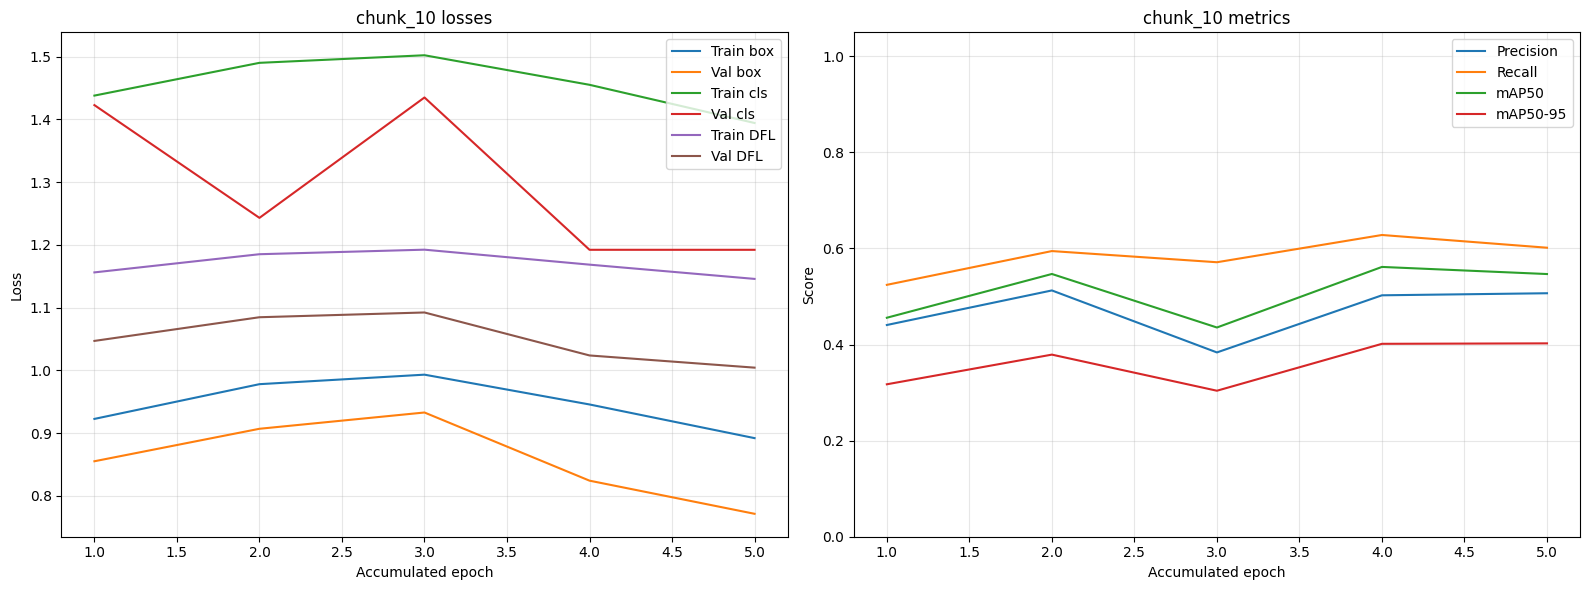

통합 그래프 저장: /content/drive/MyDrive/ai/final/model/runs/chunk_10_stream_training_graph.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

CHUNK_NAME = 'chunk_10'
TRAINING_MODE = 'whole'

csv_files = ([RUNS_ROOT / CHUNK_NAME / 'results.csv'] if TRAINING_MODE == 'whole'
             else sorted(RUNS_ROOT.glob(f'{CHUNK_NAME}_shard_*/results.csv')))
csv_files = [p for p in csv_files if p.is_file()]
if not csv_files:
    raise FileNotFoundError(f'{CHUNK_NAME} results.csv가 없습니다.')

frames = []
epoch_offset = 0
for csv_path in csv_files:
    frame = pd.read_csv(csv_path)
    frame.columns = frame.columns.str.strip()
    frame['global_epoch'] = range(epoch_offset + 1, epoch_offset + len(frame) + 1)
    frame['shard'] = csv_path.parent.name
    frames.append(frame)
    epoch_offset += len(frame)
history = pd.concat(frames, ignore_index=True)

loss_columns = [('train/box_loss', 'Train box'), ('val/box_loss', 'Val box'),
                ('train/cls_loss', 'Train cls'), ('val/cls_loss', 'Val cls'),
                ('train/dfl_loss', 'Train DFL'), ('val/dfl_loss', 'Val DFL')]
metric_columns = [('metrics/precision(B)', 'Precision'), ('metrics/recall(B)', 'Recall'),
                  ('metrics/mAP50(B)', 'mAP50'), ('metrics/mAP50-95(B)', 'mAP50-95')]
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for column, label in loss_columns:
    if column in history: axes[0].plot(history['global_epoch'], history[column], label=label)
for column, label in metric_columns:
    if column in history: axes[1].plot(history['global_epoch'], history[column], label=label)
axes[0].set(title=f'{CHUNK_NAME} losses', xlabel='Accumulated epoch', ylabel='Loss')
axes[1].set(title=f'{CHUNK_NAME} metrics', xlabel='Accumulated epoch', ylabel='Score', ylim=(0, 1.05))
for axis in axes: axis.grid(alpha=0.3); axis.legend()
plt.tight_layout()
graph_path = RUNS_ROOT / f'{CHUNK_NAME}_stream_training_graph.png'
fig.savefig(graph_path, dpi=180, bbox_inches='tight')
plt.show()
print('통합 그래프 저장:', graph_path)

best_rows = []

for csv_path in csv_files:
    frame = pd.read_csv(csv_path)
    frame.columns = frame.columns.str.strip()

    best_idx = frame['metrics/mAP50-95(B)'].idxmax()
    best = frame.loc[best_idx]

    best_rows.append({
        'shard': csv_path.parent.name,
        'Precision': best['metrics/precision(B)'],
        'Recall': best['metrics/recall(B)'],
        'mAP50': best['metrics/mAP50(B)'],
        'mAP50-95': best['metrics/mAP50-95(B)']
    })

## 7. 별도 60GB Test ZIP 최종 평가

10개 청크가 완료되고 validation으로 `global_best.pt` 선택까지 끝난 뒤에만 실행하세요. Drive의 `/recycle_yolo/test.zip`을 Colab 임시 공간에 압축 해제하여 평가하고, 끝나면 압축 해제 데이터만 삭제합니다. Test는 학습이나 모델 선택에 사용하지 않습니다.


In [ ]:
from pathlib import Path
import zipfile
import random
import shutil

# =========================
# 설정
# =========================
BASE = Path("/content/drive/MyDrive/ai/final/model")

TEST_ZIP = BASE / "test.zip"
OUT_ZIP = BASE / "test_subset.zip"

PER_CLASS = 500
SEED = 42

CLASSES = ["PET", "CAN", "PAPER", "VINYL"]

random.seed(SEED)

# =========================
# 원본 ZIP 확인
# =========================
if not TEST_ZIP.exists():
    raise FileNotFoundError(f"test.zip이 없습니다: {TEST_ZIP}")

# 기존 subset이 있으면 삭제
if OUT_ZIP.exists():
    OUT_ZIP.unlink()

# =========================
# ZIP 내부 파일 목록 읽기
# =========================
with zipfile.ZipFile(TEST_ZIP, "r") as zin:
    names = zin.namelist()

    image_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

    image_files = [
        n for n in names
        if Path(n).suffix.lower() in image_exts
        and not n.endswith("/")
    ]

    label_files = {
        Path(n).stem: n
        for n in names
        if Path(n).suffix.lower() == ".txt"
    }

    print(f"전체 이미지 수: {len(image_files)}")
    print(f"전체 라벨 수: {len(label_files)}")

    # =========================
    # 클래스별 이미지 분류
    # 파일명이 PET_123.jpg 형태라고 가정
    # =========================
    class_images = {cls: [] for cls in CLASSES}

    for img in image_files:
        stem = Path(img).stem

        for cls in CLASSES:
            if stem.upper().startswith(cls + "_"):
                class_images[cls].append(img)
                break

    # =========================
    # 클래스별 샘플링
    # =========================
    selected = []

    for cls in CLASSES:
        candidates = class_images[cls]

        if not candidates:
            print(f"[WARNING] {cls}: 이미지 없음")
            continue

        count = min(PER_CLASS, len(candidates))
        chosen = random.sample(candidates, count)

        selected.extend(chosen)

        print(f"{cls}: {len(candidates)}개 중 {count}개 선택")

    # =========================
    # subset ZIP 생성
    # =========================
    skipped_no_label = 0
    written = 0

    with zipfile.ZipFile(
        OUT_ZIP,
        "w",
        compression=zipfile.ZIP_DEFLATED
    ) as zout:

        for img in selected:
            stem = Path(img).stem

            # 대응 라벨 확인
            label = label_files.get(stem)

            if label is None:
                print(f"[SKIP] 라벨 없음: {img}")
                skipped_no_label += 1
                continue

            # 이미지 저장
            img_ext = Path(img).suffix.lower()

            img_arcname = f"images/{stem}{img_ext}"
            label_arcname = f"labels/{stem}.txt"

            zout.writestr(
                img_arcname,
                zin.read(img)
            )

            zout.writestr(
                label_arcname,
                zin.read(label)
            )

            written += 1

print("\n=========================")
print("test_subset.zip 생성 완료")
print("=========================")
print("저장 위치:", OUT_ZIP)
print("저장 이미지 수:", written)
print("라벨 없어서 제외:", skipped_no_label)
print("파일 크기:", round(OUT_ZIP.stat().st_size / (1024**3), 2), "GB")

전체 이미지 수: 18661
전체 라벨 수: 18661
PET: 6372개 중 500개 선택
CAN: 7344개 중 500개 선택
PAPER: 4945개 중 500개 선택
[WARNING] VINYL: 이미지 없음

test_subset.zip 생성 완료
저장 위치: /content/drive/MyDrive/ai/final/model/test_subset.zip
저장 이미지 수: 1500
라벨 없어서 제외: 0
파일 크기: 5.35 GB


In [ ]:
from pathlib import Path
import zipfile
import random

# =========================
# 설정
# =========================
VAL_ROOT = Path('/content/drive/MyDrive/ai/final/model/final_vinyl')
TEST_ZIP = Path('/content/drive/MyDrive/ai/final/model/test_subset.zip')

VINYL_IMG_DIR = VAL_ROOT / 'images'
VINYL_LABEL_DIR = VAL_ROOT / 'labels'

N = 500
SEED = 42

# =========================
# VINYL 이미지 찾기
# =========================
img_exts = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}

images = sorted([
    p for p in VINYL_IMG_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in img_exts
])

print(f'VINYL 전체 이미지: {len(images)}개')

if len(images) < N:
    raise ValueError(f'VINYL 이미지가 {N}개보다 적습니다. 현재 {len(images)}개')

# =========================
# 고정 랜덤 500개 선택
# =========================
random.seed(SEED)
selected = random.sample(images, N)

# =========================
# test_subset.zip에 추가
# =========================
added_img = 0
added_label = 0
missing_label = 0

with zipfile.ZipFile(TEST_ZIP, 'a', compression=zipfile.ZIP_DEFLATED) as zf:

    existing = set(zf.namelist())

    for img_path in selected:

        # 이미지
        img_arc = f'images/VINYL/{img_path.name}'

        if img_arc not in existing:
            zf.write(img_path, img_arc)
            added_img += 1

        # 대응 YOLO label
        label_path = VINYL_LABEL_DIR / f'{img_path.stem}.txt'

        if label_path.exists():
            label_arc = f'labels/VINYL/{label_path.name}'

            if label_arc not in existing:
                zf.write(label_path, label_arc)
                added_label += 1
        else:
            missing_label += 1

print('================================')
print('VINYL 추가 완료')
print(f'선택 이미지       : {len(selected)}개')
print(f'ZIP 추가 이미지   : {added_img}개')
print(f'ZIP 추가 라벨     : {added_label}개')
print(f'라벨 없는 이미지  : {missing_label}개')
print(f'저장 위치         : {TEST_ZIP}')
print('================================')

VINYL 전체 이미지: 500개
VINYL 추가 완료
선택 이미지       : 500개
ZIP 추가 이미지   : 500개
ZIP 추가 라벨     : 500개
라벨 없는 이미지  : 0개
저장 위치         : /content/drive/MyDrive/ai/final/model/test_subset.zip


In [ ]:
from collections import Counter
from pathlib import PurePosixPath
import zipfile

image_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

with zipfile.ZipFile(TEST_ZIP, "r") as zf:
    counts = Counter(
        str(PurePosixPath(info.filename).parent)
        for info in zf.infolist()
        if not info.is_dir()
        and PurePosixPath(info.filename).suffix.lower() in image_exts
    )

print("ZIP 내부 이미지 폴더별 개수")
for folder, count in sorted(counts.items()):
    print(f"{folder}: {count:,}개")
print(f"\n전체 이미지: {sum(counts.values()):,}개")

ZIP 내부 이미지 폴더별 개수
images: 1,500개
images/VINYL: 500개

전체 이미지: 2,000개


In [ ]:
import tempfile

state = load_state()
final_best = state.get('global_best')
if not final_best or not Path(final_best).exists():
    raise FileNotFoundError('global_best.pt가 없습니다.')
if not TEST_ZIP.exists():
    raise FileNotFoundError(
        f'test_subset.zip이 없습니다: {TEST_ZIP}\n'
        '큰 test.zip 전체를 이 런타임에서 풀지 말고 작은 고정 subset ZIP을 준비하세요.'
    )

test_extract = Path(
    tempfile.mkdtemp(prefix="test_subset_", dir="/content")
)
safely_extract(TEST_ZIP, test_extract)

test_root = test_extract
root = test_root.resolve()

images_dir = root / "images"
labels_dir = root / "labels"

In [ ]:
from pathlib import Path
import math
import yaml


images_dir = root / "images"
labels_dir = root / "labels"

if not images_dir.is_dir() or not labels_dir.is_dir():
    raise FileNotFoundError(f"images/ 또는 labels/ 폴더가 없습니다: {root}")

classes_file = root / "classes.txt"
if classes_file.exists():
    found = [
        line.strip()
        for line in classes_file.read_text(encoding="utf-8-sig").splitlines()
        if line.strip()
    ]
    if found != list(CLASSES):
        raise ValueError(
            f"classes.txt 순서 오류. 필요={CLASSES}, 실제={found}"
        )

image_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
images = sorted(
    p for p in images_dir.rglob("*")
    if p.is_file() and p.suffix.lower() in image_exts
)

valid_images = []
missing_images = []
bad_rows = []

for image in images:
    # images/VINYL/a.jpg → labels/VINYL/a.txt
    relative_path = image.relative_to(images_dir)
    label = labels_dir / relative_path.with_suffix(".txt")

    if not label.is_file():
        missing_images.append(image)
        print(f"[건너뜀] 이미지: {image}")
        print(f"         없는 라벨: {label}")
        continue

    # 라벨이 존재하지만 내용이 잘못된 경우는 오류로 알립니다.
    for line_number, row in enumerate(
        label.read_text(encoding="utf-8-sig").splitlines(), 1
    ):
        if not row.strip():
            continue

        try:
            values = [float(x) for x in row.split()]
            ok = (
                len(values) == 5
                and all(math.isfinite(x) for x in values)
                and values[0].is_integer()
                and 0 <= values[0] < len(CLASSES)
                and all(0 <= x <= 1 for x in values[1:])
            )
        except ValueError:
            ok = False

        if not ok:
            bad_rows.append(f"{label}:{line_number} → {row}")

    # 빈 txt 라벨은 객체 없는 이미지로 유지합니다.
    valid_images.append(image)

print(f"\n전체 이미지: {len(images):,}개")
print(f"라벨 누락으로 제외: {len(missing_images):,}개")
print(f"라벨 있는 이미지: {len(valid_images):,}개")

WORK_ROOT = Path(WORK_ROOT)
WORK_ROOT.mkdir(parents=True, exist_ok=True)

skip_list = WORK_ROOT / "final_test_skipped_images.txt"
skip_list.write_text(
    "".join(f"{p}\n" for p in missing_images),
    encoding="utf-8",
)
print(f"제외 파일 목록 저장: {skip_list}")

if bad_rows:
    print("\n잘못된 라벨:")
    for row in bad_rows[:10]:
        print(row)
    raise ValueError(f"잘못된 라벨 행 {len(bad_rows)}개를 수정해주세요.")

if not valid_images:
    raise ValueError("평가할 이미지가 없습니다.")

# 라벨 있는 이미지만 평가 목록에 저장
test_list = (WORK_ROOT / "final_test_valid_images.txt").resolve()
test_list.write_text(
    "".join(f"{p.as_posix()}\n" for p in valid_images),
    encoding="utf-8",
)

final_yaml = WORK_ROOT / "final_subset_data.yaml"
final_data = {
    "train": str((Path(VALIDATION_ROOT) / "images").resolve()),
    "val": str((Path(VALIDATION_ROOT) / "images").resolve()),
    "test": str(test_list),
    "names": {i: name for i, name in enumerate(CLASSES)},
    "nc": len(CLASSES),
}
final_yaml.write_text(
    yaml.safe_dump(final_data, allow_unicode=True, sort_keys=False),
    encoding="utf-8",
)

final_metrics = YOLO(final_best).val(
    data=str(final_yaml),
    split="test",
    imgsz=IMGSZ,
    batch=BATCH,
    device=DEVICE,
    workers=WORKERS,
    project=str(RUNS_ROOT),
    name="final_test_subset",
    plots=True,
)


전체 이미지: 2,000개
라벨 누락으로 제외: 0개
라벨 있는 이미지: 2,000개
제외 파일 목록 저장: /content/drive/MyDrive/ai/final/model/work/final_test_skipped_images.txt
Ultralytics 8.4.143 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (NVIDIA A100-SXM4-40GB, 40441MiB)
YOLO11n summary (fused): 100 layers, 2,582,932 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2737.7±1449.1 MB/s, size: 3408.7 KB)
val: Scanning /content/test_subset_ob7xd6e3/labels... 1999 images, 0 backgrounds, 1 corrupt: 100% ━━━━━━━━━━━━ 2000/2000 29.9it/s 1:07
val: /content/test_subset_ob7xd6e3/images/CAN_00004.jpg: corrupt JPEG restored and saved
val: /content/test_subset_ob7xd6e3/images/CAN_00014.jpg: corrupt JPEG restored and saved
val: /content/test_subset_ob7xd6e3/images/CAN_00046.jpg: corrupt JPEG restored and saved
val: /content/test_subset_ob7xd6e3/images/CAN_00049.jpg: corrupt JPEG restored and saved
val: /content/test_subset_ob7xd6e3/images/CAN_00084.jpg: corrupt JPEG restored and saved
val: /content/test

## 8. 최종 모델 ONNX 내보내기 및 다운로드

In [ ]:
state = load_state()
final_best = state.get('global_best')
if not final_best or not Path(final_best).exists():
    raise FileNotFoundError('global_best.pt가 없습니다.')

final_model = YOLO(final_best)
exported = Path(final_model.export(format='onnx', imgsz=IMGSZ, dynamic=False, simplify=True))
onnx_on_drive = DRIVE_ROOT / 'recycle_yolo11_final.onnx'
shutil.copy2(exported, onnx_on_drive)
print('PT 모델:', final_best)
print('ONNX 저장:', onnx_on_drive)
files.download(str(onnx_on_drive))



Ultralytics 8.4.144 🚀 Python-3.13.15 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.20GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11n summary (fused): 100 layers, 2,582,932 parameters, 0 gradients, 6.4 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/ai/final/model/global_best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 8, 8400) (5.2 MB)
requirements: Ultralytics requirement ['onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 10 packages in 157ms
Prepared 2 packages in 23ms
Installed 2 packages in 7ms
 + colorama==0.4.6
 + onnxslim==0.1.96

requirements: AutoUpdate success ✅ 0.3s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.22.0 opset 18...
ONNX: slimming with onnxslim 0.1.96...
ONNX: export success ✅ 2.3s, saved as '/content/d

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>